Ex. 1 În documentaţia pgmpy (https://pgmpy.org/examples/Monty_Hall.html) găsiţi formularea şi implementarea cele-
brei probleme Monty Hall. Cerinţa acestui exerciţiu este să explicaţi problema şi codul din implementare.

Un mod simplu de a vizualiza este urmatorul:
  Daca concurentul a ales initial usa corecta (care are o probabilitate de 1/3), atunci este mai bine sa nu schimbe
  Altfel, dupa dezvaluirea gazdei, cealalta usa sigur contine masina

  Deci, avem o sansa de 1/3 sa fie optim sa nu schimbam, si o sansa de 2/3 sa fie optim sa schimbam


Codul reprezinta o modelare a valorilor posibile pentru cele trei variabile, si a probabilitatilor conditionale, dupa care calculeaza o probabilitate conditionala inversata.
 

Ex. 2 Un medic doreşte să determine probabilitatea ca un pacient să aibă o anumită boală pulmonară (B), având în vedere
simptomele observate. Există trei variabile observabile care pot indica prezenţa bolii: tuse (T), dificultate de respiraţie
(D), radiografie anormală (X). Toate acestea sunt variabile binare.\
De asemenea, ştim că:\
● Dacă pacientul are boala (B), există o probabilitate ridicată să aibă tuse şi să apară anomalii la radiografie. \
● Dificultatea de respiraţie (D) este dependentă atât de prezenţa bolii pulmonare (B), cât şi de prezenţa tusei (T). \
Astfel, datele de probabilitate condiţionată sunt următoarele:
1. Probabilitatea apriori pentru boala pulmonară:

P(B = 1) = 0.1, P(B = 0) = 0.9;\
2. Probabilitatea condiţionată pentru tuse (T) condiţionată de boală (B):\
P(T = 1∣B = 1) = 0.8, P(T = 1∣B = 0) = 0.3; \
3. Probabilitatea condiţionată pentru radiografie anormală (X) condiţionată de boală (B): \
P(X = 1∣B = 1) = 0.9, P(X = 1∣B = 0) = 0.1;\
4. Probabilitatea condiţionată pentru dificultate de respiraţie (D), condiţionată de boală (B) şi tuse (T):

P(D = 1∣B = 1,T = 1) = 0.9, P(D = 1∣B = 1,T = 0) = 0.4; \
P(D = 1∣B = 0,T = 1) = 0.5, P(D = 1∣B = 0,T = 0) = 0.1.

a) Definiti modelul probabilist, folosind pgmpy, care sa descrie contextul de mai sus.\
b) Medicul observă că pacientul are tuse şi dificultăţi de respiraţie. Determinaţi probabilitatea ca pacientul să aibă
boala pulmonară.

c) Ulterior se descoperă (cu alte mijloace) că pacientul nu avea boala pulmonară. Care este probabilitatea ca radio-
grafia să fi fost anormală?

d) Calculaţi cele 2 probabilităţi folosind regula lui Bayes şi incărcaţi calculul fie în Markdown/Latex, fie ca foto
la foia de lucru (indicaţie: puteţi să vă folosiţi de independenţele condiţionale rezultate din modelul de reţea
bayesiană)

Modelam urmatoarea retea Bayesiana\
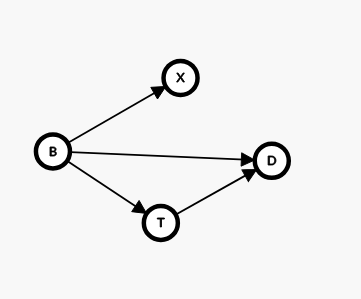

In [2]:
from pgmpy.models import DiscreteBayesianNetwork
import numpy
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import matplotlib.pyplot as plt

# Structura grafului: parintii lui D sunt B si T.
model = DiscreteBayesianNetwork([
    ("B", "T"),
    ("B", "X"),
    ("B", "D"),
    ("T", "D"),
])

# values are ordered as [state 0, state 1].
cpd_B = TabularCPD(
    variable="B", variable_card=2,
    values=[[0.9], [0.1]],
)

cpd_T = TabularCPD(
    variable="T", variable_card=2,
    values=[[0.7, 0.2], [0.3, 0.8]],
    evidence=["B"], evidence_card=[2],
)

cpd_X = TabularCPD(
    variable="X", variable_card=2,
    values=[[0.9, 0.1], [0.1, 0.9]],
    evidence=["B"], evidence_card=[2],
)

# Columns correspond to (B=0,T=0), (B=0,T=1),
# (B=1,T=0), (B=1,T=1).
cpd_D = TabularCPD(
    variable="D", variable_card=2,
    values=[
        [0.9, 0.5, 0.6, 0.1],
        [0.1, 0.5, 0.4, 0.9],
    ],
    evidence=["B", "T"], evidence_card=[2, 2],
)

model.add_cpds(cpd_B, cpd_T, cpd_X, cpd_D)
assert model.check_model()
model.get_cpds()


/home/poparobert/UAIC/III.1/PMP/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/poparobert/UAIC/III.1/PMP/venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


[<TabularCPD representing P(B:2) at 0x7f5ca7aebe00>,
 <TabularCPD representing P(T:2 | B:2) at 0x7f5ca761c7d0>,
 <TabularCPD representing P(X:2 | B:2) at 0x7f5ca6d5a850>,
 <TabularCPD representing P(D:2 | B:2, T:2) at 0x7f5ca76243e0>]

In [3]:
# b) vreem sa aflam P(B = 1 | T = 1, D = 1)
inference = VariableElimination(model)
B_TD = inference.query(
    variables=["B"],
    evidence={"T": 1, "D": 1}
)

print(B_TD)
print("P(B=1 | T=1, D=1) =", B_TD.get_value(B=1))

+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+
P(B=1 | T=1, D=1) = 0.34782608695652184


In [4]:
# c) vrem sa aflam P(X = 1 | T = 1, D = 1, B = 0)
inference = VariableElimination(model)
X_TDB = inference.query(
  variables = ["X"],
  evidence = {"T" : 1,
              "D" : 1,
              "B" : 0}
)
print(X_TDB)
print("P(X = 1 | T = 1, D = 1, B = 0) = ", X_TDB.get_value(X = 1))

+------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+
P(X = 1 | T = 1, D = 1, B = 0) =  0.1


Vrem sa aflam P(B = 1 | T = 1, D = 1) si P(X = 1 | T = 1, D = 1, B = 0)

Observatii triviale: 
$$
\begin{align}
  P(T = 0 | B = b)        &= 1 - P(T = 1 | B = b)\\
  P(D = 0 | T = t, B = b) &= 1 - P(D = 1 | T = t, B = b) \\
\end{align}
$$
Continuam: 
$$
\begin{align}
P(B = b | T = t, D = d) &= \dfrac{P(B = b, T = t, D = d)}{P(T = t, D = d)}\\

P(T = t, D = d)         &= \sum_b{P(T = t, D = d | B = b) * P(B = b)} = \sum_b{P(T = t, D = d, B = b)} \\

P(T = t, D = d, B = b)  &= P(D = d | T = t, B = b) * P(T = t | B = b) * P(B = b)

\end{align}
$$
Deci:
$$
\begin{align}
P(B = 1 | T = 1, D = 1) &= \dfrac{P(B = 1, T = 1, D = 1)}{P(T = 1, D = 1)} \\
                        &= \dfrac{P(B = 1, T = 1, D = 1)}{P(T = 1, D = 1, B = 0) + P(T = 1, D = 1, B = 1)} \\
                        &= \dfrac{P(D = 1 | T = 1, B = 1) * P(T = 1 | B = 1) * P(B = 1)}{P(D = 1 | T = 1, B = 1) * P(T = 1 | B = 1) * P(B = 1) + P(D = 1 | T = 1, B = 0) * P(T = 1 | B = 0) * P(B = 0)} \\
                        &= \dfrac{0.9 * 0.8 * 0.1}{0.9 * 0.8 * 0.1 + 0.5 * 0.3 * 0.9} \\
                        &= \dfrac{0.072}{0.072 + 0.135}\\
                        &= \dfrac{0.072}{0.207}\\
                        &= 0.34782608695
\end{align}
$$

Faptul ca $X \perp D$ si $X \perp T$ ne impune ca P(X = x | T = t, B = b, D = d) = P(X = x| B = b) $\rightarrow$ P(X = 1 | T = 1, B = 0, D = 1) = P(X = 1 | B = 0) = 0.1

Ex. 3 Un joc între doi jucători, J0 şi J1, se desfăşoară în felul următor:\
● se aruncă mai întâi cu o monedă (normală) pentru a decide cine începe: J0 sau J1;\
● în prima rundă, jucătorul desemnat aruncă cu propriul zar; fie n numărul obţinut;\
● în a doua rundă, celălalt jucător aruncă cu moneda proprie de 2n ori; fie m numărul de steme obţinute.\
Jucătorul din prima rundă câştigă dacă n ≥ m, în caz contrar câştigând jucătorul din a doua rundă. Mai ştim că
jucătorul J1 este necinstit, el aducând o monedă măsluită, cu probabilitatea de obţinere a stemei egală cu 4/7. În schimb,
moneda jucătorului J0 este normală, iar cele două zaruri sunt şi ele normale.\
a) Estimaţi care dintre cei doi jucători are şansele cele mai mari de câştig, simulând un joc de 10000 ori.\
b) Folosind pgmpy, definiţi o reţea Bayesiană care sa descrie contextul de mai sus.\
c) Folosind modelul de mai sus, determinaţi cine e cel mai probabil să fi început jocul, ştiind că în a doua rundă s-a
obţinut o singură stemă.

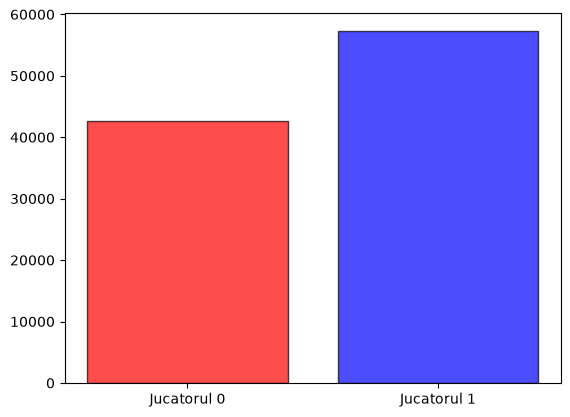

In [7]:
# presimt ca jucatorul J1 are sanse mai mari de castig
def game(coins = [0.5, 4/7]):
  player = numpy.random.randint(0, 2)
  n      = numpy.random.randint(1, 7)
  m      = numpy.random.binomial(2 * n, coins[1 - player])
  if m <= n:
    return player
  else:
    return 1 - player

possible_winners = [0, 1]
observed_winners = [game() for i in range(100000)]
counts           = [observed_winners.count(c) for c in possible_winners]
# print(winners)
plt.bar(possible_winners, counts, alpha=0.7, color=['red', 'blue'], edgecolor='black')
plt.xticks(range(len(possible_winners)), [f'Jucatorul {x}' for x in possible_winners])
plt.show()

Modelam jocul ca retea Bayesiana cu variabilele:
- $S \in \{0, 1\}$ - jucatorul care incepe (ales cu o moneda corecta)
- $N \in \{1, \dots, 6\}$ - rezultatul zarului aruncat de jucatorul $S$
- $M \in \{0, \dots, 12\}$ - numarul de steme obtinute de celalalt jucator in $2N$ aruncari cu moneda lui
- $W \in \{0, 1\}$ - castigatorul

Muchii: $S \rightarrow M$, $N \rightarrow M$, $S \rightarrow W$, $N \rightarrow W$, $M \rightarrow W$

$$
\begin{align}
P(S = s) &= \tfrac{1}{2}, \quad P(N = n) = \tfrac{1}{6} \\
M \mid S = s, N = n &\sim \text{Binomial}(2n,\ p_{1 - s}), \quad p_0 = \tfrac{1}{2},\ p_1 = \tfrac{4}{7} \\
W &= \begin{cases} S & \text{daca } M \le N \\ 1 - S & \text{altfel} \end{cases}
\end{align}
$$

In [11]:
from math import comb

coins   = [0.5, 4/7]         # P(stema) pentru moneda lui J0, respectiv J1
players = [0, 1]
dice    = list(range(1, 7))
heads   = list(range(0, 13)) # 2n <= 12

def binomial(k, n, p):
  return comb(n, k) * p**k * (1 - p)**(n - k)

game_model = DiscreteBayesianNetwork([
    ("S", "M"),
    ("N", "M"),
    ("S", "W"),
    ("N", "W"),
    ("M", "W"),
])

cpd_S = TabularCPD(
    variable="S", variable_card=2,
    values=[[0.5], [0.5]],
    state_names={"S": players},
)

cpd_N = TabularCPD(
    variable="N", variable_card=6,
    values=[[1/6] for n in dice],
    state_names={"N": dice},
)

cpd_M = TabularCPD(
    variable="M", variable_card=13,
    values=[[binomial(m, 2 * n, coins[1 - s]) for s in players for n in dice]
            for m in heads],
    evidence=["S", "N"], evidence_card=[2, 6],
    state_names={"M": heads, "S": players, "N": dice},
)

cpd_W = TabularCPD(
    variable="W", variable_card=2,
    values=[[float(w == (s if m <= n else 1 - s)) for s in players for n in dice for m in heads]
            for w in players],
    evidence=["S", "N", "M"], evidence_card=[2, 6, 13],
    state_names={"W": players, "S": players, "N": dice, "M": heads},
)

game_model.add_cpds(cpd_S, cpd_N, cpd_M, cpd_W)
assert game_model.check_model()

game_inference = VariableElimination(game_model)
W = game_inference.query(variables=["W"])
print(W)
print("Simulare:", [c / len(observed_winners) for c in counts])

+------+----------+
| W    |   phi(W) |
+======+==========+
| W(0) |   0.4267 |
+------+----------+
| W(1) |   0.5733 |
+------+----------+
Simulare: [0.42695, 0.57305]


In [13]:
inference = VariableElimination(game_model)
S = inference.query(variables = ["S"],
                    evidence = {"M" : 1})
print(S)

+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.4529 |
+------+----------+
| S(1) |   0.5471 |
+------+----------+
